## Dependencies

In [18]:
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
import catboost as cb
from sklearn.metrics import f1_score, precision_score, recall_score, roc_auc_score, confusion_matrix, r2_score, accuracy_score
import matplotlib.pyplot as plt
import shap

In [ ]:
import sys
sys.path.append('../..')

%load_ext autoreload
%autoreload 2

from libs import ios
from libs.tools_comparison import ToolsComparison
from libs.inference import categorical

## Setup

In [3]:
VERSION = 2
DATA = f'../../data/v{VERSION}/chinese_names'
RESULTS = f'../../results/v{VERSION}/chinese_gender'

DIR_TOOL_W = ios.path_join(RESULTS, 'tool_w')
DIR_TOOL_R = ios.path_join(RESULTS, 'tool_r')
DIR_TOOL_N = ios.path_join(RESULTS, 'tool_n')
DIR_GT = ios.path_join(DATA, 'annotations')

## Data

In [4]:
tc = ToolsComparison(dir_tool_w=DIR_TOOL_W, dir_tool_r=DIR_TOOL_R, dir_tool_n=DIR_TOOL_N, dir_gt=DIR_GT)
tc.load_data()

In [5]:
tc.compare_unique_chinese_given_names()
tc.df_ch_genders.head(2)

,ngender_r,gender_w,0,1,2,3,4,5,6,7,...,std,std_ngender_rnw,std_ngender_rn,std_ngender_rw,std_ngender_nw,mode,mode_ngender_rnw,mode_ngender_rn,mode_ngender_rw,mode_ngender_nw
givenname,,,,,,,,,,,,,,,,,,,,,
俊池,0.30315,male,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,0.161985,0.035063,0.151575,0.186638,NaN,0.30315,0.30315,0.30315,0.373277
建军,0.14830,male,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,0.125561,0.079598,0.074150,0.153748,NaN,0.14830,0.14830,0.14830,0.307495


In [6]:
tc.df_ch_genders_gt

,givenname,ngender_r,gender_w,0,1,2,3,4,5,6,...,std,std_ngender_rnw,std_ngender_rn,std_ngender_rw,std_ngender_nw,mode,mode_ngender_rnw,mode_ngender_rn,mode_ngender_rw,mode_ngender_nw
0,佳玉,0.65875,female,5.0,5.0,4.0,4.0,4.0,5.0,5.0,...,0.026385,0.179325,0.034447,0.170625,0.205072,1.00,0.65875,0.65875,0.65875,0.589855
1,凤良,0.51775,male,5.0,2.0,5.0,4.0,3.0,4.0,4.0,...,0.093592,0.288260,0.078453,0.258875,0.337328,1.00,0.51775,0.51775,0.51775,0.674656
2,璟,0.61075,male,3.0,2.0,5.0,2.0,3.0,3.0,3.0,...,0.009373,0.284924,0.006437,0.305375,0.298938,0.50,0.61075,0.61075,0.61075,0.597875
3,怀珂,0.44970,female,4.0,4.0,5.0,2.0,4.0,3.0,3.0,...,0.080062,0.254874,0.009902,0.275150,0.265248,0.75,0.44970,0.44970,0.44970,0.469505
4,馨心,0.76760,female,5.0,5.0,5.0,5.0,5.0,5.0,5.0,...,0.028731,0.175482,0.098477,0.116200,0.214677,1.00,0.76760,0.76760,0.76760,0.570647
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
95,中锐,0.22115,male,2.0,2.0,2.0,2.0,1.0,1.0,2.0,...,0.020031,0.152576,0.075170,0.110575,0.185745,0.25,0.22115,0.22115,0.22115,0.371490
96,能韫,0.44305,female,2.0,2.0,2.0,1.0,2.0,2.0,2.0,...,-0.078204,0.279070,0.032383,0.278475,0.310858,0.25,0.44305,0.44305,0.44305,0.378284
97,祖应,0.30570,female,2.0,2.0,2.0,2.0,1.0,2.0,2.0,...,-0.078204,0.326181,0.002377,0.347150,0.344773,0.25,0.30570,0.30570,0.30570,0.310454
98,浩琛,0.18925,male,1.0,1.0,1.0,1.0,1.0,2.0,2.0,...,-0.089976,0.146394,0.084577,0.094625,0.179202,0.00,0.18925,0.18925,0.18925,0.358403


In [ ]:
RANDOM_STATE = 12345
TEST_SIZE = 0.2
GRID = {'iterations': [100, 150, 200, 300],
        'learning_rate': [0.01, 0.03, 0.05, 0.1],
        'depth': [2, 4, 6, 8],
        'l2_leaf_reg': [0.1, 0.2, 0.5, 1, 3],
        }

LABELS = categorical.GENDER_LABELS_3

STRATEGY = {1:{'cuts':[0.445, 0.541], 'gt_agg':'mean'},
            2:{'cuts':[0.45, 0.71], 'gt_agg':'mean'},
            3:{'cuts':[0.3, 0.7], 'gt_agg':'median'},
            4:{'cuts':[0.4, 0.6], 'gt_agg':'mode'},
           }

COLS = ['ngender_r', 'ngender_n', 'ngender_w',
        'gender_w', 'gender_n',
        'mean_ngender_rn', 'mean_ngender_rw', 'mean_ngender_nw', 
        'median_ngender_rn', 'median_ngender_rw', 'median_ngender_nw',
        'mode_ngender_rn', 'mode_ngender_rw', 'mode_ngender_nw',
        'mean_ngender_rnw', 'median_ngender_rnw', 'mode_ngender_rnw',
        'mean', 'median', 'mode']

GT_AGGS = ['mean', 'median', 'mode']

In [8]:
STRATEGY_ID = 2

In [9]:
cuts = STRATEGY[STRATEGY_ID]['cuts']
gt_agg = STRATEGY[STRATEGY_ID]['gt_agg']
var_x = f"gender_{gt_agg}"
thresholds = [(-1,cuts[0]),(cuts[0],cuts[1]),(cuts[1],2)]

data = tc.df_ch_genders_gt.copy()[COLS]
data.loc[:,var_x] = categorical._convert_numeric_to_categorical_by_thresholds(data[gt_agg], thresholds, LABELS)
data.loc[:,var_x] = pd.Categorical(data[var_x], categories=LABELS, ordered=True)
data.drop(columns=GT_AGGS, inplace=True)
data


,ngender_r,ngender_n,ngender_w,gender_w,gender_n,mean_ngender_rn,mean_ngender_rw,mean_ngender_nw,median_ngender_rn,median_ngender_rw,median_ngender_nw,mode_ngender_rn,mode_ngender_rw,mode_ngender_nw,mean_ngender_rnw,median_ngender_rnw,mode_ngender_rnw,gender_mean
0,0.65875,0.589855,1.0,female,female,0.624303,0.829375,0.794928,0.624303,0.829375,0.794928,0.65875,0.65875,0.589855,0.749535,0.658750,0.65875,female
1,0.51775,0.674656,0.0,male,female,0.596203,0.258875,0.337328,0.596203,0.258875,0.337328,0.51775,0.51775,0.674656,0.397469,0.517750,0.51775,neutral
2,0.61075,0.597875,0.0,male,female,0.604313,0.305375,0.298938,0.604313,0.305375,0.298938,0.61075,0.61075,0.597875,0.402875,0.597875,0.61075,male
3,0.44970,0.469505,1.0,female,male,0.459602,0.724850,0.734752,0.459602,0.724850,0.734752,0.44970,0.44970,0.469505,0.639735,0.469505,0.44970,neutral
4,0.76760,0.570647,1.0,female,female,0.669123,0.883800,0.785323,0.669123,0.883800,0.785323,0.76760,0.76760,0.570647,0.779416,0.767600,0.76760,female
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
95,0.22115,0.371490,0.0,male,male,0.296320,0.110575,0.185745,0.296320,0.110575,0.185745,0.22115,0.22115,0.371490,0.197547,0.221150,0.22115,male
96,0.44305,0.378284,1.0,female,male,0.410667,0.721525,0.689142,0.410667,0.721525,0.689142,0.44305,0.44305,0.378284,0.607111,0.443050,0.44305,male
97,0.30570,0.310454,1.0,female,male,0.308077,0.652850,0.655227,0.308077,0.652850,0.655227,0.30570,0.30570,0.310454,0.538718,0.310454,0.30570,male
98,0.18925,0.358403,0.0,male,male,0.273827,0.094625,0.179202,0.273827,0.094625,0.179202,0.18925,0.18925,0.358403,0.182551,0.189250,0.18925,male


In [10]:
data[var_x].value_counts()

gender_mean
male       46
female     30
neutral    24
Name: count, dtype: int64

In [11]:
# X, y
feature_names = ['ngender_r', 'ngender_n', 'ngender_w']

# Encode target variable
label_encoder = LabelEncoder()
label_encoder.fit(LABELS)
var_y = f"{var_x}_encoded"
data[var_y] = label_encoder.transform(data[var_x])

# categroical features
cat_features = [c for c in feature_names if c in ['gender_w','gender_n']]

# Split dataset
X = data[feature_names]  # Features
y = data[[var_y]]  # Target variable
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=TEST_SIZE, random_state=RANDOM_STATE, stratify=y)
train_dataset = cb.Pool(X_train, y_train) 

# Model
model = cb.CatBoostClassifier(verbose=0, 
                              cat_features=cat_features, 
                              eval_metric="MultiClass") #["F1", "TotalF1", "MultiClass","Accuracy", "CrossEntropy"])

# Tuning
model.grid_search(GRID, train_dataset, verbose=False)



bestTest = 0.7707398793
bestIteration = 99


bestTest = 0.6780727785
bestIteration = 93


bestTest = 0.6505581496
bestIteration = 97


bestTest = 0.6270305312
bestIteration = 36


bestTest = 0.7731318992
bestIteration = 99


bestTest = 0.6779603847
bestIteration = 97


bestTest = 0.657567248
bestIteration = 97


bestTest = 0.6277238711
bestIteration = 36


bestTest = 0.7798856936
bestIteration = 99


bestTest = 0.6805369673
bestIteration = 97


bestTest = 0.6535935891
bestIteration = 97


bestTest = 0.6345142638
bestIteration = 35


bestTest = 0.7903641148
bestIteration = 99


bestTest = 0.6844010978
bestIteration = 97


bestTest = 0.6510939961
bestIteration = 97


bestTest = 0.633348483
bestIteration = 59


bestTest = 0.8222526641
bestIteration = 99


bestTest = 0.6926438679
bestIteration = 96


bestTest = 0.659534478
bestIteration = 99


bestTest = 0.6266053605
bestIteration = 96


bestTest = 0.71786533
bestIteration = 149


bestTest = 0.6601703172
bestIteration = 149


bestTest = 0

{'params': {'depth': 2,
  'learning_rate': 0.1,
  'l2_leaf_reg': 3,
  'iterations': 100},
 'cv_results': defaultdict(list,
             {'iterations': [0,
               1,
               2,
               3,
               4,
               5,
               6,
               7,
               8,
               9,
               10,
               11,
               12,
               13,
               14,
               15,
               16,
               17,
               18,
               19,
               20,
               21,
               22,
               23,
               24,
               25,
               26,
               27,
               28,
               29,
               30,
               31,
               32,
               33,
               34,
               35,
               36,
               37,
               38,
               39,
               40,
               41,
               42,
               43,
               44,
               45,

In [12]:
# Get best parameters
best_params = model.get_params()
print("Best Parameters:", best_params)

# Get best model
best_model = model.get_best_score()
print("Best score:", best_model)

Best Parameters: {'verbose': 0, 'eval_metric': 'MultiClass', 'cat_features': [], 'depth': 2, 'learning_rate': 0.1, 'l2_leaf_reg': 3, 'iterations': 100}
Best score: {'learn': {'MultiClass': 0.37117599526638617}}


In [13]:
# Predict class labels and probabilities
y_pred = model.predict(X_test)
y_pred_proba = model.predict_proba(X_test)

# labels
y_pred_labels = label_encoder.inverse_transform(y_pred)
y_test_labels = label_encoder.inverse_transform(y_test)

# Compute Accuracy
accuracy = accuracy_score(y_test_labels, y_pred_labels)

# Compute F1-score (macro for multi-class)
f1 = f1_score(y_test_labels, y_pred_labels, average='macro', labels=LABELS)

# Compute Precision & Recall (macro for multi-class)
precision = precision_score(y_test_labels, y_pred_labels, average='macro', labels=LABELS)
recall = recall_score(y_test_labels, y_pred_labels, average='macro', labels=LABELS)

# Compute AUC (only if y_pred_proba has multiple columns for multi-class)
auc = roc_auc_score(y_test, y_pred_proba, multi_class='ovr')

# Compute Confusion Matrix
conf_matrix = confusion_matrix(y_test_labels, y_pred_labels, labels=LABELS)

# Print Metrics
print(f"Accuracy: {accuracy:.4f}")
print(f"F1-score: {f1:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall: {recall:.4f}")
print(f"AUC: {auc:.4f}")
print("Confusion Matrix:\n", conf_matrix)


Accuracy: 0.9000
F1-score: 0.8833
Precision: 0.9394
Recall: 0.8667
AUC: 0.9666
Confusion Matrix:
 [[9 0 0]
 [2 3 0]
 [0 0 6]]


/home/espinl/.conda/envs/py12chinam/lib/python3.12/site-packages/sklearn/preprocessing/_label.py:153: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)
/home/espinl/.conda/envs/py12chinam/lib/python3.12/site-packages/sklearn/preprocessing/_label.py:153: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)


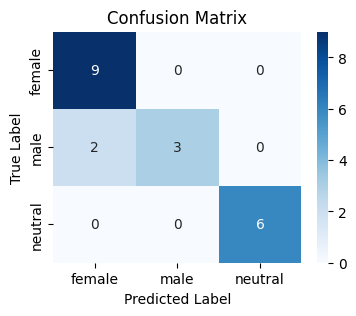

In [14]:
# Plot Confusion Matrix
plt.figure(figsize=(4,3))
sns.heatmap(conf_matrix, annot=True, fmt="d", cmap="Blues",
            xticklabels=label_encoder.classes_, yticklabels=label_encoder.classes_)
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("Confusion Matrix")
plt.show()
plt.close()

In [15]:
# Predict class labels and probabilities
y_pred = model.predict(X)
y_pred_proba = model.predict_proba(X)

# labels
y_pred_labels = label_encoder.inverse_transform(y_pred)
y_test_labels = label_encoder.inverse_transform(y)

# Compute Accuracy
accuracy = accuracy_score(y_test_labels, y_pred_labels)

# Compute F1-score (macro for multi-class)
f1 = f1_score(y_test_labels, y_pred_labels, average='macro', labels=LABELS)

# Compute Precision & Recall (macro for multi-class)
precision = precision_score(y_test_labels, y_pred_labels, average='macro', labels=LABELS)
recall = recall_score(y_test_labels, y_pred_labels, average='macro', labels=LABELS)

# Compute AUC (only if y_pred_proba has multiple columns for multi-class)
auc = roc_auc_score(y, y_pred_proba, multi_class='ovr')

# Compute Confusion Matrix
conf_matrix = confusion_matrix(y_test_labels, y_pred_labels, labels=LABELS)

# Print Metrics
print(f"Accuracy: {accuracy:.4f}")
print(f"F1-score: {f1:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall: {recall:.4f}")
print(f"AUC: {auc:.4f}")
print("Confusion Matrix:\n", conf_matrix)


Accuracy: 0.8900
F1-score: 0.8611
Precision: 0.8993
Recall: 0.8539
AUC: 0.9626
Confusion Matrix:
 [[45  1  0]
 [ 6 14  4]
 [ 0  0 30]]


/home/espinl/.conda/envs/py12chinam/lib/python3.12/site-packages/sklearn/preprocessing/_label.py:153: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)
/home/espinl/.conda/envs/py12chinam/lib/python3.12/site-packages/sklearn/preprocessing/_label.py:153: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)


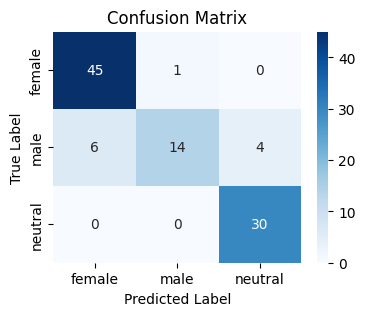

In [16]:
# Plot Confusion Matrix
plt.figure(figsize=(4,3))
sns.heatmap(conf_matrix, annot=True, fmt="d", cmap="Blues",
            xticklabels=label_encoder.classes_, yticklabels=label_encoder.classes_)
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("Confusion Matrix")
plt.show()
plt.close()

Text(0.5, 0, 'CatBoost Feature Importance')

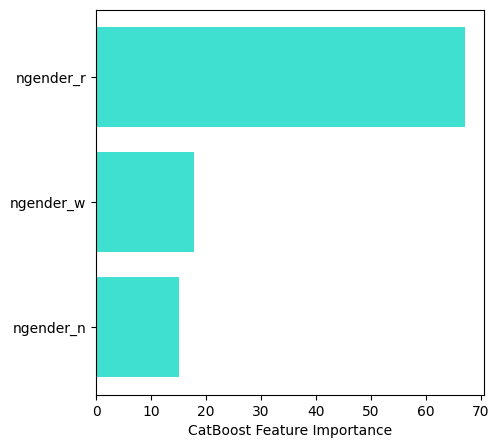

In [17]:
sorted_feature_importance = model.feature_importances_.argsort()
sorted_feature_names = [feature_names[id] for id in sorted_feature_importance]
fig,ax = plt.subplots(1,1,figsize=(5,5))
ax.barh(sorted_feature_names, 
        model.feature_importances_[sorted_feature_importance], 
        color='turquoise')
ax.set_xlabel("CatBoost Feature Importance")